# Loan Default Prediction with Neural Networks

Predicting which loans will default at application time, using 50,000 personal loans issued in 2012–2013 (15.6% defaulted).

**Changes from the original coursework version**
- **Loss function:** binary cross-entropy (`nn.BCELoss`) replaces mean squared error. It is the standard loss for a sigmoid classifier.
- **Early stopping:** each model now reloads the weights from its best validation epoch before evaluation (previously the last epoch's weights were used), and Models 1 and 3 save to separate checkpoint files.
- **Risk-segment analysis:** evaluated on held-out test loans only (previously all 50,000 loans, including training data).
- **Data loading:** reads `data/loan_data.csv` locally instead of Google Drive, with pandas-3-compatible median imputation.

Results shown were produced on CPU. A GPU run gives very slightly different numbers.


In [1]:
# Should be on GPU runtime if on running on google colab

import torch
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from torch.utils.data import TensorDataset, DataLoader
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import roc_auc_score, classification_report, roc_curve, auc, confusion_matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import os
import random
import math
from imblearn.under_sampling import RandomUnderSampler
import matplotlib.pyplot as plt

print("Num GPUs Available: ", torch.cuda.device_count())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Num GPUs Available:  0
Using device: cpu


In [2]:
# Setting seed to pytorch to not get random output

def set_seed(seed=42):
    """Locks down all randomness for full reproducibility."""
    # 1. Lock standard Python
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)

    # 2. Lock NumPy (Used by Scikit-Learn for train_test_split)
    np.random.seed(seed)

    # 3. Lock PyTorch CPU operations
    torch.manual_seed(seed)

    # 4. Lock PyTorch GPU operations
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    # 5. Force deterministic math on the GPU
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(42)

In [3]:
# Data is loaded from the local data/ folder (originally run in Google Colab with Google Drive)

In [4]:
# Importing the dataset


dataset_path = 'data/loan_data.csv'

data = pd.read_csv(dataset_path)
print("Dataset loaded successfully :")
display(data.head())


Dataset loaded successfully :


,loan_amnt,int_rate,home_ownership,annual_inc,verification_status,dti,delinq_2yrs,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,mths_since_last_major_derog,tot_cur_bal,total_credit_rv,loan_is_bad,cluster,cluster_label
0,11200,6.62,OWN,108000.0,Not Verified,12.52,0,NaN,NaN,9,0,NaN,187717.0,66400.0,False,2,Low Risk
1,10000,11.14,MORTGAGE,65000.0,Not Verified,9.58,0,NaN,NaN,9,0,NaN,16623.0,22400.0,True,1,Medium Risk
2,8000,16.29,RENT,35000.0,Not Verified,27.84,0,NaN,NaN,12,0,NaN,17938.0,24900.0,False,1,Medium Risk
3,16000,7.90,MORTGAGE,110000.0,Verified,28.87,0,NaN,NaN,21,0,NaN,372771.0,31500.0,False,1,Medium Risk
4,4000,7.90,MORTGAGE,155000.0,Source Verified,17.87,0,NaN,NaN,7,0,NaN,331205.0,46000.0,False,1,Medium Risk


#Data Preprocessing and selection

Taking data which is available at application time. Grade is not includeded because it is highly coreleated with int_rate

In [5]:

data_clean = data[[
  'loan_amnt',
  'int_rate',
  'home_ownership',
  'annual_inc',
  'verification_status',
  'dti',
  'delinq_2yrs',
  'mths_since_last_delinq',
  'mths_since_last_record',
  'open_acc',
  'pub_rec',
  'mths_since_last_major_derog',
  'tot_cur_bal',
  'total_credit_rv',
  'loan_is_bad'
]]

data_clean.head()

,loan_amnt,int_rate,home_ownership,annual_inc,verification_status,dti,delinq_2yrs,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,mths_since_last_major_derog,tot_cur_bal,total_credit_rv,loan_is_bad
0,11200,6.62,OWN,108000.0,Not Verified,12.52,0,NaN,NaN,9,0,NaN,187717.0,66400.0,False
1,10000,11.14,MORTGAGE,65000.0,Not Verified,9.58,0,NaN,NaN,9,0,NaN,16623.0,22400.0,True
2,8000,16.29,RENT,35000.0,Not Verified,27.84,0,NaN,NaN,12,0,NaN,17938.0,24900.0,False
3,16000,7.90,MORTGAGE,110000.0,Verified,28.87,0,NaN,NaN,21,0,NaN,372771.0,31500.0,False
4,4000,7.90,MORTGAGE,155000.0,Source Verified,17.87,0,NaN,NaN,7,0,NaN,331205.0,46000.0,False


In [6]:
data_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 15 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   loan_amnt                    50000 non-null  int64  
 1   int_rate                     50000 non-null  float64
 2   home_ownership               50000 non-null  str    
 3   annual_inc                   50000 non-null  float64
 4   verification_status          50000 non-null  str    
 5   dti                          50000 non-null  float64
 6   delinq_2yrs                  50000 non-null  int64  
 7   mths_since_last_delinq       21874 non-null  float64
 8   mths_since_last_record       2532 non-null   float64
 9   open_acc                     50000 non-null  int64  
 10  pub_rec                      50000 non-null  int64  
 11  mths_since_last_major_derog  7120 non-null   float64
 12  tot_cur_bal                  35382 non-null  float64
 13  total_credit_rv            

Converting object variables to categorical variables

In [7]:
cols = [ "home_ownership", "verification_status"]
data_clean[cols] = data[cols].astype("category")
data_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 15 columns):
 #   Column                       Non-Null Count  Dtype   
---  ------                       --------------  -----   
 0   loan_amnt                    50000 non-null  int64   
 1   int_rate                     50000 non-null  float64 
 2   home_ownership               50000 non-null  category
 3   annual_inc                   50000 non-null  float64 
 4   verification_status          50000 non-null  category
 5   dti                          50000 non-null  float64 
 6   delinq_2yrs                  50000 non-null  int64   
 7   mths_since_last_delinq       21874 non-null  float64 
 8   mths_since_last_record       2532 non-null   float64 
 9   open_acc                     50000 non-null  int64   
 10  pub_rec                      50000 non-null  int64   
 11  mths_since_last_major_derog  7120 non-null   float64 
 12  tot_cur_bal                  35382 non-null  float64 
 13  total_credit

In [8]:
print(data_clean['home_ownership'].unique())
print(data_clean['verification_status'].unique())

['OWN', 'MORTGAGE', 'RENT', 'NONE', 'OTHER']
Categories (5, str): ['MORTGAGE', 'NONE', 'OTHER', 'OWN', 'RENT']
['Not Verified', 'Verified', 'Source Verified']
Categories (3, str): ['Not Verified', 'Source Verified', 'Verified']


Binary encoding for home_ownership and  verification_status

In [9]:
cat_cols =  ['home_ownership', 'verification_status']
data_clean = pd.get_dummies(data_clean, columns=cat_cols, prefix= cat_cols, drop_first=True)
data_clean.head()

,loan_amnt,int_rate,annual_inc,dti,delinq_2yrs,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,mths_since_last_major_derog,tot_cur_bal,total_credit_rv,loan_is_bad,home_ownership_NONE,home_ownership_OTHER,home_ownership_OWN,home_ownership_RENT,verification_status_Source Verified,verification_status_Verified
0,11200,6.62,108000.0,12.52,0,NaN,NaN,9,0,NaN,187717.0,66400.0,False,False,False,True,False,False,False
1,10000,11.14,65000.0,9.58,0,NaN,NaN,9,0,NaN,16623.0,22400.0,True,False,False,False,False,False,False
2,8000,16.29,35000.0,27.84,0,NaN,NaN,12,0,NaN,17938.0,24900.0,False,False,False,False,True,False,False
3,16000,7.90,110000.0,28.87,0,NaN,NaN,21,0,NaN,372771.0,31500.0,False,False,False,False,False,False,True
4,4000,7.90,155000.0,17.87,0,NaN,NaN,7,0,NaN,331205.0,46000.0,False,False,False,False,False,True,False


Checking no of null values

In [10]:
data_clean.isnull().sum() / len(data) * 100

loan_amnt                               0.000
int_rate                                0.000
annual_inc                              0.000
dti                                     0.000
delinq_2yrs                             0.000
mths_since_last_delinq                 56.252
mths_since_last_record                 94.936
open_acc                                0.000
pub_rec                                 0.000
mths_since_last_major_derog            85.760
tot_cur_bal                            29.236
total_credit_rv                        29.236
loan_is_bad                             0.000
home_ownership_NONE                     0.000
home_ownership_OTHER                    0.000
home_ownership_OWN                      0.000
home_ownership_RENT                     0.000
verification_status_Source Verified     0.000
verification_status_Verified            0.000
dtype: float64

Dropping these 3 features because they have over 50% of data as NULL

In [11]:
data_clean=data_clean.drop(columns=['mths_since_last_delinq', 'mths_since_last_record', 'mths_since_last_major_derog'])

data_clean

,loan_amnt,int_rate,annual_inc,dti,delinq_2yrs,open_acc,pub_rec,tot_cur_bal,total_credit_rv,loan_is_bad,home_ownership_NONE,home_ownership_OTHER,home_ownership_OWN,home_ownership_RENT,verification_status_Source Verified,verification_status_Verified
0,11200,6.62,108000.0,12.52,0,9,0,187717.0,66400.0,False,False,False,True,False,False,False
1,10000,11.14,65000.0,9.58,0,9,0,16623.0,22400.0,True,False,False,False,False,False,False
2,8000,16.29,35000.0,27.84,0,12,0,17938.0,24900.0,False,False,False,False,True,False,False
3,16000,7.90,110000.0,28.87,0,21,0,372771.0,31500.0,False,False,False,False,False,False,True
4,4000,7.90,155000.0,17.87,0,7,0,331205.0,46000.0,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,22000,13.99,94000.0,15.38,0,14,0,NaN,NaN,True,False,False,False,True,False,True
49996,4000,8.90,35360.0,21.14,0,8,0,NaN,NaN,True,False,False,False,True,True,False
49997,27050,18.25,78000.0,19.42,0,9,0,NaN,NaN,False,False,False,False,False,False,True
49998,9600,7.90,45000.0,19.52,0,16,0,NaN,NaN,False,False,False,False,False,False,False


Median Imputation

In [12]:
data_clean['tot_cur_bal'] = data_clean['tot_cur_bal'].fillna(data_clean['tot_cur_bal'].median())
data_clean['total_credit_rv'] = data_clean['total_credit_rv'].fillna(data_clean['total_credit_rv'].median())

In [13]:
data_clean

,loan_amnt,int_rate,annual_inc,dti,delinq_2yrs,open_acc,pub_rec,tot_cur_bal,total_credit_rv,loan_is_bad,home_ownership_NONE,home_ownership_OTHER,home_ownership_OWN,home_ownership_RENT,verification_status_Source Verified,verification_status_Verified
0,11200,6.62,108000.0,12.52,0,9,0,187717.0,66400.0,False,False,False,True,False,False,False
1,10000,11.14,65000.0,9.58,0,9,0,16623.0,22400.0,True,False,False,False,False,False,False
2,8000,16.29,35000.0,27.84,0,12,0,17938.0,24900.0,False,False,False,False,True,False,False
3,16000,7.90,110000.0,28.87,0,21,0,372771.0,31500.0,False,False,False,False,False,False,True
4,4000,7.90,155000.0,17.87,0,7,0,331205.0,46000.0,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,22000,13.99,94000.0,15.38,0,14,0,72117.0,22800.0,True,False,False,False,True,False,True
49996,4000,8.90,35360.0,21.14,0,8,0,72117.0,22800.0,True,False,False,False,True,True,False
49997,27050,18.25,78000.0,19.42,0,9,0,72117.0,22800.0,False,False,False,False,False,False,True
49998,9600,7.90,45000.0,19.52,0,16,0,72117.0,22800.0,False,False,False,False,False,False,False


In [14]:
print(data_clean['loan_is_bad'].value_counts())

loan_is_bad
False    42186
True      7814
Name: count, dtype: int64


In [15]:
# normalising the data

data_clean['annual_inc'] = np.log1p(data_clean['annual_inc'])
data_clean['loan_amnt'] = np.log1p(data_clean['loan_amnt'])

The data is imballanced as number of defaulted customers is very less. Stratification and undersampling is done.

In [16]:
# Splitting the data

X = data_clean.drop(columns=['loan_is_bad'])
y = data_clean['loan_is_bad']

print(X.shape)
print(y.shape)

(50000, 15)
(50000,)


In [17]:
X.head(), y.head()

(   loan_amnt  int_rate  annual_inc    dti  delinq_2yrs  open_acc  pub_rec  \
 0   9.323758      6.62   11.589896  12.52            0         9        0   
 1   9.210440     11.14   11.082158   9.58            0         9        0   
 2   8.987322     16.29   10.463132  27.84            0        12        0   
 3   9.680406      7.90   11.608245  28.87            0        21        0   
 4   8.294300      7.90   11.951187  17.87            0         7        0   
 
    tot_cur_bal  total_credit_rv  home_ownership_NONE  home_ownership_OTHER  \
 0     187717.0          66400.0                False                 False   
 1      16623.0          22400.0                False                 False   
 2      17938.0          24900.0                False                 False   
 3     372771.0          31500.0                False                 False   
 4     331205.0          46000.0                False                 False   
 
    home_ownership_OWN  home_ownership_RENT  \
 0     

Train, Validation and Test split. Train 70%, Validation 15% and Test 15%

In [18]:
random_seed = 42

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.15, random_state=random_seed, stratify=y)

X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.1764, random_state=random_seed, stratify=y_temp)

# Keep the original row numbers of the test loans for the risk-segment analysis
test_idx = X_test.index


In [19]:
print("Training set size:", X_train.shape)
print("Validation set size:", X_val.shape)
print("Test set size:", X_test.shape)

print("\nTarget distribution in training (%):")
print(y_train.value_counts(normalize=True) * 100)

print("\nTarget distribution in test (%):")
print(y_test.value_counts(normalize=True) * 100)

print("\nTarget distribution in test (%):")
print(y_val.value_counts(normalize=True) * 100)

Training set size: (35003, 15)
Validation set size: (7497, 15)
Test set size: (7500, 15)

Target distribution in training (%):
loan_is_bad
False    84.372768
True     15.627232
Name: proportion, dtype: float64

Target distribution in test (%):
loan_is_bad
False    84.373333
True     15.626667
Name: proportion, dtype: float64

Target distribution in test (%):
loan_is_bad
False    84.36708
True     15.63292
Name: proportion, dtype: float64


In [20]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(35003, 15)
(7497, 15)
(7500, 15)


Since only true in target variable is only 15%, undersampling is done as lot of data is there for model to train on

In [21]:
ru = RandomUnderSampler(sampling_strategy = 1.0, random_state=42)

X_train_ru, y_train_ru = ru.fit_resample(X_train, y_train)

print("Before Random under sampling:", y_train.value_counts())
print("After Random under sampling:", y_train_ru.value_counts())

Before Random under sampling: loan_is_bad
False    29533
True      5470
Name: count, dtype: int64
After Random under sampling: loan_is_bad
False    5470
True     5470
Name: count, dtype: int64


Converting to tensors

In [22]:
X_train_ru_tensor = torch.tensor(X_train_ru, dtype=torch.float32)
y_train_ru_tensor = torch.tensor(y_train_ru.values, dtype=torch.float32).reshape(-1, 1)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).reshape(-1, 1)

X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val.values, dtype=torch.float32).reshape(-1, 1)

In [23]:
print(X_train_ru_tensor.shape)
print(y_train_ru_tensor.shape)
print(X_val_tensor.shape)
print(y_val_tensor.shape)
print(X_test_tensor.shape)
print(y_test_tensor.shape)

torch.Size([10940, 15])
torch.Size([10940, 1])
torch.Size([7497, 15])
torch.Size([7497, 1])
torch.Size([7500, 15])
torch.Size([7500, 1])


In [24]:
train_dataset = TensorDataset(X_train_ru_tensor, y_train_ru_tensor)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

val_loader = DataLoader(TensorDataset(X_val_tensor, y_val_tensor), batch_size=32, shuffle=False)

test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [25]:
input_size=X_train_ru_tensor.shape[1]
input_size

15

#Model creation

##Model 1

In [26]:
class LoanDefaultModel(nn.Module):

    def __init__(self, input_size):
        super(LoanDefaultModel, self).__init__()

        self.layers = nn.Sequential(

            # Layer 1
            nn.Linear(input_size, 32), # Input size is 15
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(0.3),

            # Layer 2
            nn.Linear(32, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.3),


            # Layer 3
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(0.3),

            # Layer 4
            nn.Linear(32, 16),
            nn.BatchNorm1d(16),
            nn.ReLU(),
            nn.Dropout(0.2),

            # Output layer (1 neuron because we are predicting a single binary outcome)
            nn.Linear(16, 1),

            # Sigmoid activation squashes the final output into a probability between 0 and 1
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.layers(x)


In [27]:
model1 = LoanDefaultModel(input_size)
criterion = nn.BCELoss()  # binary cross-entropy: the standard loss for a sigmoid classifier
optimiser = optim.Adam(model1.parameters(), lr=0.0005, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimiser, mode='min', factor=0.5, patience=5)

In [28]:
epochs = 100
patience = 15
best_val_loss = float('inf')
epochs_no_improve = 0
early_stop = False

train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []

model1.to(device)

for epoch in range(epochs):
    if early_stop:
        print(f"Early stopping triggered at epoch {epoch}")
        break

    # --- Training Phase ---
    model1.train()
    running_loss = 0.0
    train_correct = 0
    train_total = 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimiser.zero_grad()
        outputs = model1(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimiser.step()

        running_loss += loss.item() * inputs.size(0)


        predicted = (outputs > 0.5).float()
        train_correct += (predicted == labels).sum().item()
        train_total += labels.size(0)

    epoch_train_loss = running_loss / len(train_loader.dataset)
    epoch_train_acc = train_correct / train_total

    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_acc)

    # --- Validation Phase ---
    model1.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model1(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * inputs.size(0)


            predicted = (outputs > 0.5).float()
            val_correct += (predicted == labels).sum().item()
            val_total += labels.size(0)

    epoch_val_loss = val_loss / len(val_loader.dataset)
    epoch_val_acc = val_correct / val_total

    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_acc)

    # Update Learning Rate Scheduler based on validation loss
    scheduler.step(epoch_val_loss)

    # --- Early Stopping Logic ---
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        epochs_no_improve = 0
        # Save the best model
        torch.save(model1.state_dict(), 'best_model1.pth')
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            early_stop = True

    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1:03d}/{epochs} | Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f} | Train Acc: {epoch_train_acc:.4f} | Val Acc: {epoch_val_acc:.4f}")

# Restore the weights from the epoch with the lowest validation loss
model1.load_state_dict(torch.load('best_model1.pth'))
print(f'Restored best Model 1 weights (val loss {best_val_loss:.4f})')


Epoch 005/100 | Train Loss: 0.6650 | Val Loss: 0.6689 | Train Acc: 0.6016 | Val Acc: 0.5644


Epoch 010/100 | Train Loss: 0.6586 | Val Loss: 0.6681 | Train Acc: 0.6124 | Val Acc: 0.5606


Epoch 015/100 | Train Loss: 0.6566 | Val Loss: 0.6671 | Train Acc: 0.6149 | Val Acc: 0.5765


Epoch 020/100 | Train Loss: 0.6571 | Val Loss: 0.6703 | Train Acc: 0.6180 | Val Acc: 0.5705


Epoch 025/100 | Train Loss: 0.6535 | Val Loss: 0.6594 | Train Acc: 0.6246 | Val Acc: 0.5813


Epoch 030/100 | Train Loss: 0.6516 | Val Loss: 0.6565 | Train Acc: 0.6224 | Val Acc: 0.6020


Early stopping triggered at epoch 32
Restored best Model 1 weights (val loss 0.6450)


Evaluation

In [29]:
# Define MSE explicitly for the evaluation phase
mse_criterion = nn.MSELoss()

model1.eval() # testing mode
mse_values = [] # collect the MSE scores

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs, targets = inputs.to(device), targets.to(device)

        # Predict the test data (These are probabilities between 0 and 1)
        outputs = model1(inputs)

        # Calculate Mean Squared Error for the batch
        # (Comparing the raw probability to the actual 0.0 or 1.0 target)
        mse = mse_criterion(outputs, targets.view_as(outputs))

        mse_values.append(mse.item()) # add to the list of  MSE values

# Calculate and print the average MSE
avg_mse = np.mean(mse_values)
print(f"Average MSE (Brier Score) on test set: {avg_mse:.4f}")

Average MSE (Brier Score) on test set: 0.2259


In [30]:
model1.eval()
all_actuals = []
all_pred_probs = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        outputs = model1(inputs)
        all_pred_probs.extend(outputs.cpu().numpy())
        all_actuals.extend(targets.cpu().numpy())

all_pred_probs = np.array(all_pred_probs)
all_actuals = np.array(all_actuals)

# Calculate ROC-AUC
auc_score = roc_auc_score(all_actuals, all_pred_probs)

# Calculate Recall using a standard 0.5 threshold
all_pred_classes = (all_pred_probs > 0.5).astype(int)

print(f"Global ROC-AUC Score: {auc_score:.4f}")
print("\nClassification Report:")
print(classification_report(all_actuals, all_pred_classes))




Global ROC-AUC Score: 0.6539

Classification Report:
              precision    recall  f1-score   support

         0.0       0.90      0.61      0.73      6328
         1.0       0.23      0.62      0.33      1172

    accuracy                           0.61      7500
   macro avg       0.56      0.62      0.53      7500
weighted avg       0.79      0.61      0.67      7500



Model 1 is showing good ROC-AUC score and recall for default, and decent recall for non default and overall accuracy

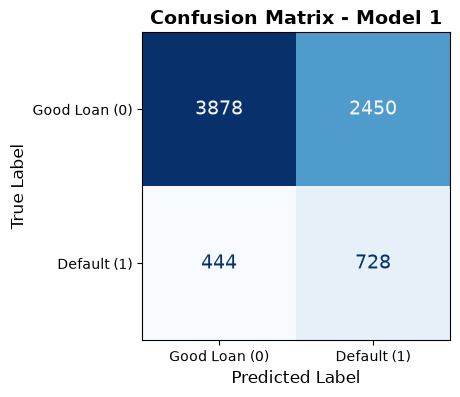

In [31]:
cm = confusion_matrix(all_actuals, all_pred_classes)


#  Build the Plot

fig, ax = plt.subplots(figsize=(4, 4))


labels = ['Good Loan (0)', 'Default (1)']


disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)


disp.plot(ax=ax, cmap='Blues', colorbar=False, text_kw={'fontsize': 14})


plt.title('Confusion Matrix - Model 1', fontweight='bold', fontsize=14)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)

plt.show()

## Model 2

In this model, we are using similar architecture to Model 1, but without dropout layer, batchnorm layer, early stopping and scheduler

In [32]:
class LoanDefaultModel2(nn.Module):

    def __init__(self, input_size):
        super(LoanDefaultModel2, self).__init__()

        self.layers = nn.Sequential(

            # Layer 1
            nn.Linear(input_size, 32), # Input size is 15
            nn.ReLU(),

            # Layer 2
            nn.Linear(32, 64),
            nn.ReLU(),


            # Layer 3
            nn.Linear(64, 32),
            nn.ReLU(),

            # Layer 4
            nn.Linear(32, 16),
            nn.ReLU(),

            # Output layer (1 neuron because we are predicting a single binary outcome)
            nn.Linear(16, 1),

            # Sigmoid activation squashes the final output into a probability between 0 and 1
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.layers(x)

In [33]:
model2 = LoanDefaultModel2(input_size)
criterion = nn.BCELoss()  # binary cross-entropy: the standard loss for a sigmoid classifier
optimiser = optim.Adam(model2.parameters(), lr=0.0005, weight_decay=1e-4)

In [34]:
epochs = 100
best_val_loss = float('inf')
epochs_no_improve = 0
early_stop = False

train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []

model2.to(device)

for epoch in range(epochs):
    if early_stop:
        print(f"Early stopping triggered at epoch {epoch}")
        break

    # --- Training Phase ---
    model2.train()
    running_loss = 0.0
    train_correct = 0
    train_total = 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimiser.zero_grad()
        outputs = model2(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimiser.step()

        running_loss += loss.item() * inputs.size(0)

        predicted = (outputs > 0.5).float()
        train_correct += (predicted == labels).sum().item()
        train_total += labels.size(0)

    epoch_train_loss = running_loss / len(train_loader.dataset)
    epoch_train_acc = train_correct / train_total

    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_acc)

    # --- Validation Phase ---
    model2.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model2(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * inputs.size(0)


            predicted = (outputs > 0.5).float()
            val_correct += (predicted == labels).sum().item()
            val_total += labels.size(0)

    epoch_val_loss = val_loss / len(val_loader.dataset)
    epoch_val_acc = val_correct / val_total

    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_acc)

    # Update Learning Rate Scheduler based on validation loss
    #scheduler.step(epoch_val_loss)

    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1:03d}/{epochs} | Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f} | Train Acc: {epoch_train_acc:.4f} | Val Acc: {epoch_val_acc:.4f}")

Epoch 005/100 | Train Loss: 0.6489 | Val Loss: 0.6879 | Train Acc: 0.6255 | Val Acc: 0.5466


Epoch 010/100 | Train Loss: 0.6458 | Val Loss: 0.6479 | Train Acc: 0.6261 | Val Acc: 0.6022


Epoch 015/100 | Train Loss: 0.6431 | Val Loss: 0.6365 | Train Acc: 0.6322 | Val Acc: 0.6224


Epoch 020/100 | Train Loss: 0.6396 | Val Loss: 0.6885 | Train Acc: 0.6340 | Val Acc: 0.5630


Epoch 025/100 | Train Loss: 0.6360 | Val Loss: 0.6522 | Train Acc: 0.6385 | Val Acc: 0.6128


Epoch 030/100 | Train Loss: 0.6319 | Val Loss: 0.6663 | Train Acc: 0.6448 | Val Acc: 0.5826


... (10 outputs left out)

Epoch 085/100 | Train Loss: 0.5803 | Val Loss: 0.7171 | Train Acc: 0.6927 | Val Acc: 0.5974


Epoch 090/100 | Train Loss: 0.5755 | Val Loss: 0.6958 | Train Acc: 0.7011 | Val Acc: 0.6058


Epoch 095/100 | Train Loss: 0.5697 | Val Loss: 0.7140 | Train Acc: 0.7031 | Val Acc: 0.6004


Epoch 100/100 | Train Loss: 0.5649 | Val Loss: 0.7609 | Train Acc: 0.7084 | Val Acc: 0.5681


Evaluation

In [35]:
model2.eval()
all_actuals = []
all_pred_probs = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        outputs = model2(inputs)
        all_pred_probs.extend(outputs.cpu().numpy())
        all_actuals.extend(targets.cpu().numpy())

all_pred_probs = np.array(all_pred_probs)
all_actuals = np.array(all_actuals)

# Calculate ROC-AUC
auc_score = roc_auc_score(all_actuals, all_pred_probs)

# Calculate predictions using a standard 0.5 threshold
all_pred_classes = (all_pred_probs > 0.5).astype(int)

print(f"Global ROC-AUC Score: {auc_score:.4f}")
print("\nClassification Report:")
print(classification_report(all_actuals, all_pred_classes))

Global ROC-AUC Score: 0.6056

Classification Report:
              precision    recall  f1-score   support

         0.0       0.88      0.56      0.69      6328
         1.0       0.20      0.59      0.30      1172

    accuracy                           0.57      7500
   macro avg       0.54      0.58      0.49      7500
weighted avg       0.78      0.57      0.63      7500



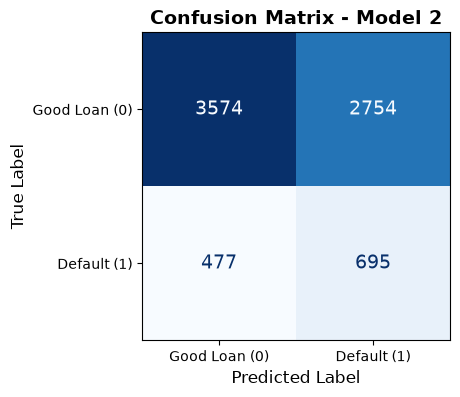

In [36]:
cm = confusion_matrix(all_actuals, all_pred_classes)

fig, ax = plt.subplots(figsize=(4, 4))


labels = ['Good Loan (0)', 'Default (1)']


disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)


disp.plot(ax=ax, cmap='Blues', colorbar=False, text_kw={'fontsize': 14})


plt.title('Confusion Matrix - Model 2', fontweight='bold', fontsize=14)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)

plt.show()

The overall the model is poorly compared to model 1. So it is not chosen.

## Model 3 (Model 1 with SMOTE Data)

Now we are going to compare if model 1 performs better SMOTE data (over sampling)

In [37]:
sm = SMOTE(random_state=42)
X_train_smote, y_train_smote = sm.fit_resample(X_train, y_train)

print("Before SMOTE:", y_train.value_counts())
print("After SMOTE:", y_train_smote.value_counts())

Before SMOTE: loan_is_bad
False    29533
True      5470
Name: count, dtype: int64
After SMOTE: loan_is_bad
False    29533
True     29533
Name: count, dtype: int64


In [38]:
X_train_smote_tensor = torch.tensor(X_train_smote, dtype=torch.float32)
y_train_smote_tensor = torch.tensor(y_train_smote.values, dtype=torch.float32).reshape(-1, 1)

train_smote_dataset = TensorDataset(X_train_smote_tensor, y_train_smote_tensor)
train_smote_loader = DataLoader(train_smote_dataset, batch_size=32, shuffle=True)

In [39]:
model1_smote = LoanDefaultModel(input_size)
criterion = nn.BCELoss()  # binary cross-entropy: the standard loss for a sigmoid classifier
optimiser = optim.Adam(model1_smote.parameters(), lr=0.0005, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimiser, mode='min', factor=0.5, patience=5)

In [40]:
epochs = 100
patience = 15
best_val_loss = float('inf')
epochs_no_improve = 0
early_stop = False

train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []

model1_smote.to(device)

for epoch in range(epochs):
    if early_stop:
        print(f"Early stopping triggered at epoch {epoch}")
        break

    # --- Training Phase ---
    model1_smote.train()
    running_loss = 0.0
    train_correct = 0
    train_total = 0

    for inputs, labels in train_smote_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimiser.zero_grad()
        outputs = model1_smote(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimiser.step()

        running_loss += loss.item() * inputs.size(0)


        predicted = (outputs > 0.5).float()
        train_correct += (predicted == labels).sum().item()
        train_total += labels.size(0)

    epoch_train_loss = running_loss / len(train_smote_loader.dataset)
    epoch_train_acc = train_correct / train_total

    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_acc)

    # --- Validation Phase ---
    model1_smote.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model1_smote(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * inputs.size(0)


            predicted = (outputs > 0.5).float()
            val_correct += (predicted == labels).sum().item()
            val_total += labels.size(0)

    epoch_val_loss = val_loss / len(val_loader.dataset)
    epoch_val_acc = val_correct / val_total

    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_acc)

    # Update Learning Rate Scheduler based on validation loss
    scheduler.step(epoch_val_loss)

    # --- Early Stopping Logic ---
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        epochs_no_improve = 0
        # Save the best model
        torch.save(model1_smote.state_dict(), 'best_model3.pth')
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            early_stop = True

    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1:03d}/{epochs} | Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f} | Train Acc: {epoch_train_acc:.4f} | Val Acc: {epoch_val_acc:.4f}")

# Restore the weights from the epoch with the lowest validation loss
model1_smote.load_state_dict(torch.load('best_model3.pth'))
print(f'Restored best Model 3 weights (val loss {best_val_loss:.4f})')


Epoch 005/100 | Train Loss: 0.6495 | Val Loss: 0.6615 | Train Acc: 0.6239 | Val Acc: 0.5541


Epoch 010/100 | Train Loss: 0.6466 | Val Loss: 0.6570 | Train Acc: 0.6287 | Val Acc: 0.5749


Epoch 015/100 | Train Loss: 0.6445 | Val Loss: 0.6676 | Train Acc: 0.6310 | Val Acc: 0.5736


Early stopping triggered at epoch 18
Restored best Model 3 weights (val loss 0.6554)


Evaluation

In [41]:
model1_smote.eval()
all_actuals = []
all_pred_probs = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        outputs = model1_smote(inputs)
        all_pred_probs.extend(outputs.cpu().numpy())
        all_actuals.extend(targets.cpu().numpy())

all_pred_probs = np.array(all_pred_probs)
all_actuals = np.array(all_actuals)

# Calculate ROC-AUC
auc_score = roc_auc_score(all_actuals, all_pred_probs)

# Calculate pred using a standard 0.5 threshold
all_pred_classes = (all_pred_probs > 0.5).astype(int)

print(f"Global ROC-AUC Score: {auc_score:.4f}")
print("\nClassification Report:")
print(classification_report(all_actuals, all_pred_classes))

Global ROC-AUC Score: 0.6509

Classification Report:
              precision    recall  f1-score   support

         0.0       0.90      0.56      0.69      6328
         1.0       0.22      0.66      0.33      1172

    accuracy                           0.57      7500
   macro avg       0.56      0.61      0.51      7500
weighted avg       0.79      0.57      0.63      7500



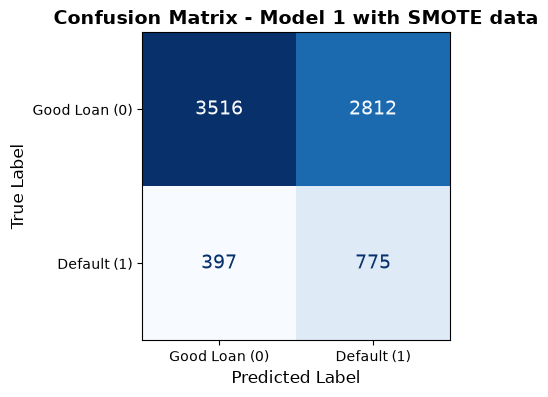

In [42]:
cm = confusion_matrix(all_actuals, all_pred_classes)




fig, ax = plt.subplots(figsize=(4, 4))


labels = ['Good Loan (0)', 'Default (1)']


disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)


disp.plot(ax=ax, cmap='Blues', colorbar=False, text_kw={'fontsize': 14})


plt.title('Confusion Matrix - Model 1 with SMOTE data', fontweight='bold', fontsize=14)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)

plt.show()

While the recall has improved slightly for default, for non default it reduced (which means we are rejecting more good customers) and ROC score has reduced. So it is not chosen  

## Plotting ROC of 3 models

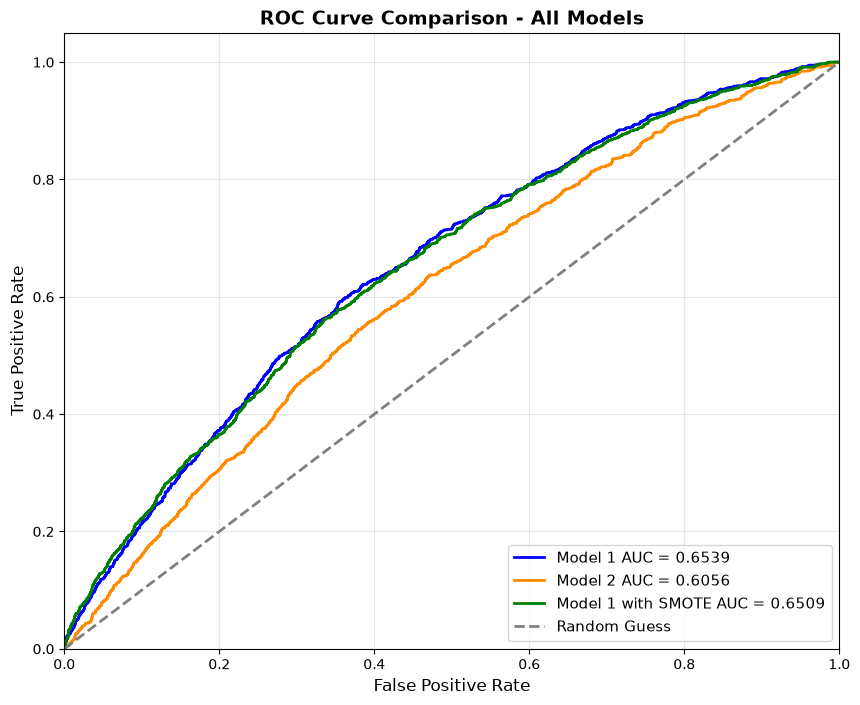

In [43]:
def get_model_probs(model_to_test, dataloader):
    model_to_test.eval()
    actuals = []
    pred_probs = []

    with torch.no_grad():
        for inputs, targets in dataloader:
            inputs, targets = inputs.to(device), targets.to(device)


            probs = model_to_test(inputs)

            pred_probs.extend(probs.cpu().numpy())
            actuals.extend(targets.cpu().numpy())

    return np.array(actuals), np.array(pred_probs)


y_true, probs_m1 = get_model_probs(model1, test_loader)
_, probs_m2 = get_model_probs(model2, test_loader)
_, probs_m3 = get_model_probs(model1_smote, test_loader)


#  Calculate ROC and AUC for each model

fpr1, tpr1, _ = roc_curve(y_true, probs_m1)
auc1 = auc(fpr1, tpr1)

fpr2, tpr2, _ = roc_curve(y_true, probs_m2)
auc2 = auc(fpr2, tpr2)

fpr3, tpr3, _ = roc_curve(y_true, probs_m3)
auc3 = auc(fpr3, tpr3)




plt.figure(figsize=(10, 8))

# Model 1 (Undersampling)
plt.plot(fpr1, tpr1, color='blue', lw=2, label=f'Model 1 AUC = {auc1:.4f}')

# Model 2
plt.plot(fpr2, tpr2, color='darkorange', lw=2, label=f'Model 2 AUC = {auc2:.4f}')

# Model 1 with smote
plt.plot(fpr3, tpr3, color='green', lw=2, label=f'Model 1 with SMOTE AUC = {auc3:.4f}')

# Random Guessing Line
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--', label='Random Guess')


plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curve Comparison - All Models', fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=11)
plt.grid(alpha=0.3)

plt.show()

Based on the performance of the models, model 1 is chosen when evalating whole dataset as it has high ROC-AUC and good recall scores for both default and non default loans, which will help to minimise the losses.

# Cluster Evaluation

In [44]:
# Risk-segment labels (1 = Medium, 2 = Low, 3 = High risk) are stored in the dataset's 'cluster' column
data_clean['cluster'] = data['cluster']


clustered_clean_datasets = {}

for cluster_id in sorted(data_clean['cluster'].unique()):

    # Filter the clean dataframe for just that cluster
    split_df = data_clean[data_clean['cluster'] == cluster_id].copy()

    # Drop the cluster column so your neural network doesn't train on it
    split_df = split_df.drop(columns=['cluster'])


    clustered_clean_datasets[cluster_id] = split_df

    print(f"Clean Cluster {cluster_id} successfully isolated with {len(split_df)} rows.")


#data_clean = data.drop(columns=['cluster'])

Clean Cluster 1 successfully isolated with 24702 rows.
Clean Cluster 2 successfully isolated with 15516 rows.
Clean Cluster 3 successfully isolated with 9782 rows.


## Model 1


PERFORMANCE FOR CLUSTER 1
Cluster 1 ROC-AUC Score: 0.6154

Classification Report for Cluster 1:
              precision    recall  f1-score   support

         0.0       0.89      0.54      0.67      3098
         1.0       0.21      0.65      0.32       597

    accuracy                           0.55      3695
   macro avg       0.55      0.59      0.49      3695
weighted avg       0.78      0.55      0.61      3695


PERFORMANCE FOR CLUSTER 2
Cluster 2 ROC-AUC Score: 0.6268

Classification Report for Cluster 2:
              precision    recall  f1-score   support

         0.0       0.91      0.90      0.90      2129
         1.0       0.17      0.19      0.18       232

    accuracy                           0.83      2361
   macro avg       0.54      0.54      0.54      2361
weighted avg       0.84      0.83      0.83      2361


PERFORMANCE FOR CLUSTER 3
Cluster 3 ROC-AUC Score: 0.6167

Classification Report for Cluster 3:
              precision    recall  f1-score   support



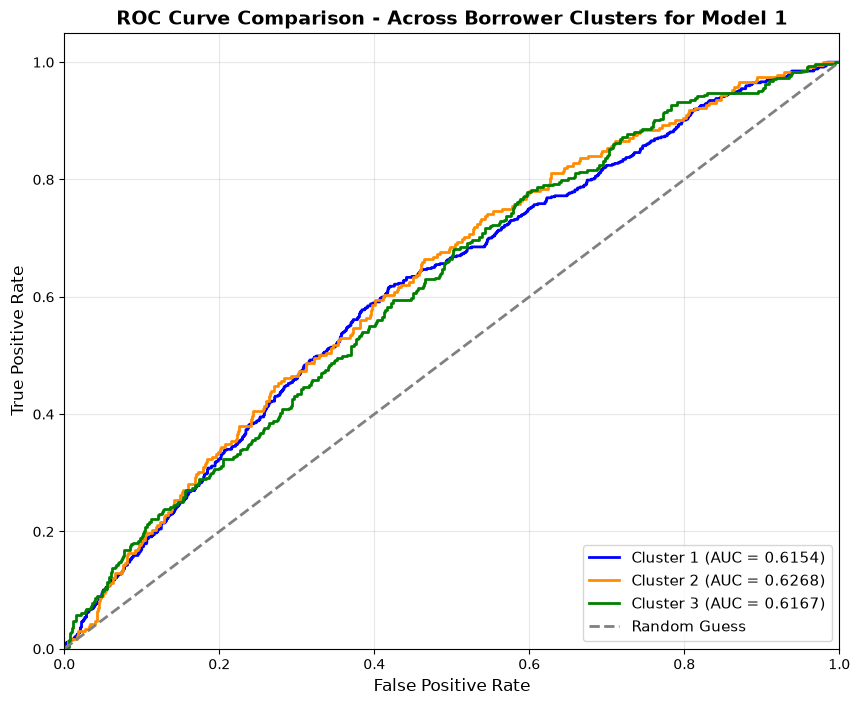

In [45]:
model1.eval()

# Ask the model where it is currently living
device = next(model1.parameters()).device

# Create a dictionary to store the results for each cluster!
cluster_results = {}

test_data = data_clean.loc[test_idx]  # evaluate on held-out test loans only

for cluster_id in sorted(test_data['cluster'].unique()):
    print(f"\n{'='*50}")
    print(f"PERFORMANCE FOR CLUSTER {cluster_id}")
    print(f"{'='*50}")

    # Isolate the data for just this cluster
    cluster_data = test_data[test_data['cluster'] == cluster_id]

    # Split into features (X) and target (y)
    X_cluster = cluster_data.drop(columns=['loan_is_bad', 'cluster'])
    y_cluster = cluster_data['loan_is_bad']

    # Scale the features
    X_cluster_scaled = scaler.transform(X_cluster)

    # Convert to PyTorch Tensors
    X_tensor = torch.tensor(X_cluster_scaled, dtype=torch.float32)
    y_tensor = torch.tensor(y_cluster.values, dtype=torch.float32).reshape(-1, 1)


    cluster_dataset = TensorDataset(X_tensor, y_tensor)
    cluster_loader = DataLoader(cluster_dataset, batch_size=32, shuffle=False)

    all_actuals = []
    all_pred_probs = []

    with torch.no_grad():
        for inputs, targets in cluster_loader:
            inputs, targets = inputs.to(device), targets.to(device)


            probs = model1(inputs)

            all_pred_probs.extend(probs.cpu().numpy())
            all_actuals.extend(targets.cpu().numpy())

    all_pred_probs = np.array(all_pred_probs)
    all_actuals = np.array(all_actuals)

    # SAVE the actuals and probabilities into our dictionary for plotting later!
    cluster_results[cluster_id] = {
        'actuals': all_actuals,
        'probs': all_pred_probs
    }

    # Convert probabilities to strict 0 or 1 predictions for the classification report
    all_pred_classes = (all_pred_probs > 0.5).astype(int)


    if len(np.unique(all_actuals)) > 1:
        cluster_auc = roc_auc_score(all_actuals, all_pred_probs)
        print(f"Cluster {cluster_id} ROC-AUC Score: {cluster_auc:.4f}\n")
    else:
        print("ROC-AUC Score: Cannot calculate (only one class present)\n")

    print(f"Classification Report for Cluster {cluster_id}:")
    print(classification_report(all_actuals, all_pred_classes, zero_division=0))





plt.figure(figsize=(10, 8))
colors = ['blue', 'darkorange', 'green']

# Loop through our saved dictionary to plot each line
for i, (cluster_id, data) in enumerate(cluster_results.items()):
    actuals = data['actuals']
    probs = data['probs']

    # Only plot if the cluster has both classes (0 and 1)
    if len(np.unique(actuals)) > 1:
        fpr, tpr, _ = roc_curve(actuals, probs)
        cluster_auc = auc(fpr, tpr)

        plt.plot(fpr, tpr, color=colors[i % len(colors)], lw=2,
                 label=f'Cluster {cluster_id} (AUC = {cluster_auc:.4f})')

# Plot the Random Guess Line
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--', label='Random Guess')


plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curve Comparison - Across Borrower Clusters for Model 1', fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=11)
plt.grid(alpha=0.3)

plt.show()

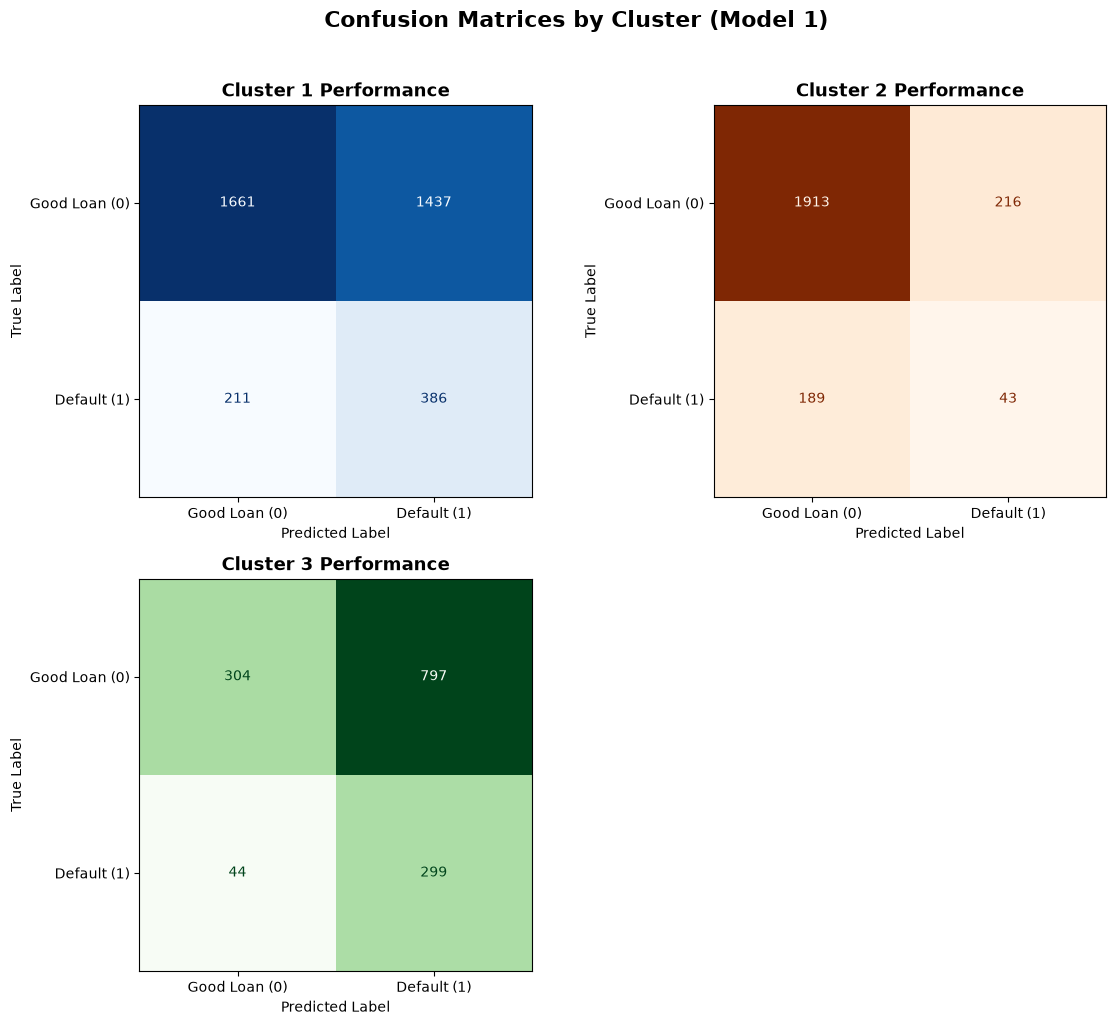

In [46]:
num_clusters = len(cluster_results)
cols = 2
rows = math.ceil(num_clusters / cols)

fig, axes = plt.subplots(rows, cols, figsize=(12, 5 * rows))


axes = axes.flatten()

labels = ['Good Loan (0)', 'Default (1)']
colormaps = ['Blues', 'Oranges', 'Greens', 'Purples', 'Reds']




for idx, (cluster_id, data) in enumerate(cluster_results.items()):
    actuals = data['actuals']
    probs = data['probs']

    # Apply threshold
    preds = (probs > 0.5).astype(int)

    # Generate the matrix
    cm = confusion_matrix(actuals, preds)

    # Plot it on the correct subplot
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
    disp.plot(ax=axes[idx], cmap=colormaps[idx % len(colormaps)], colorbar=False)

    # Format the titles
    axes[idx].set_title(f'Cluster {cluster_id} Performance', fontweight='bold', fontsize=13)
    axes[idx].set_xlabel('Predicted Label')
    axes[idx].set_ylabel('True Label')


for i in range(num_clusters, len(axes)):
    fig.delaxes(axes[i])

plt.suptitle('Confusion Matrices by Cluster (Model 1)',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()

plt.show()

## Model 2


PERFORMANCE FOR CLUSTER 1
Cluster 1 ROC-AUC Score: 0.5734

Classification Report for Cluster 1:
              precision    recall  f1-score   support

         0.0       0.87      0.51      0.64      3098
         1.0       0.19      0.61      0.29       597

    accuracy                           0.52      3695
   macro avg       0.53      0.56      0.47      3695
weighted avg       0.76      0.52      0.58      3695


PERFORMANCE FOR CLUSTER 2
Cluster 2 ROC-AUC Score: 0.5827

Classification Report for Cluster 2:
              precision    recall  f1-score   support

         0.0       0.91      0.77      0.83      2129
         1.0       0.14      0.34      0.20       232

    accuracy                           0.73      2361
   macro avg       0.53      0.55      0.52      2361
weighted avg       0.84      0.73      0.77      2361


PERFORMANCE FOR CLUSTER 3
Cluster 3 ROC-AUC Score: 0.5677

Classification Report for Cluster 3:
              precision    recall  f1-score   support



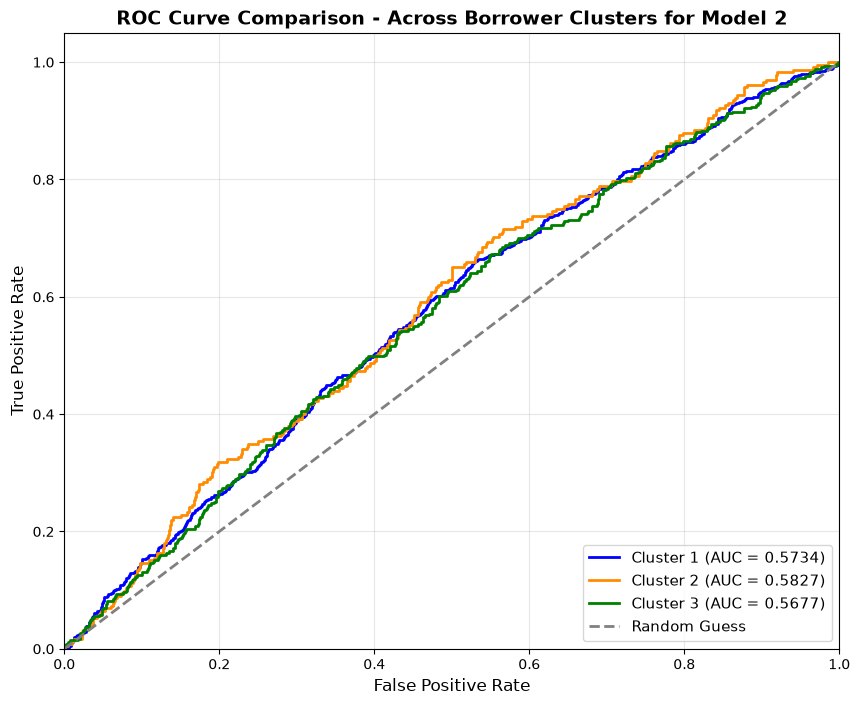

In [47]:
model2.eval()

# Ask the model where it is currently living
device = next(model2.parameters()).device


cluster_results = {}

test_data = data_clean.loc[test_idx]  # evaluate on held-out test loans only

for cluster_id in sorted(test_data['cluster'].unique()):
    print(f"\n{'='*50}")
    print(f"PERFORMANCE FOR CLUSTER {cluster_id}")
    print(f"{'='*50}")

    # Isolate the data for just this cluster
    cluster_data = test_data[test_data['cluster'] == cluster_id]

    # Split into features (X) and target (y)
    X_cluster = cluster_data.drop(columns=['loan_is_bad', 'cluster'])
    y_cluster = cluster_data['loan_is_bad']

    # Scale the features
    X_cluster_scaled = scaler.transform(X_cluster)

    # Convert to PyTorch Tensors
    X_tensor = torch.tensor(X_cluster_scaled, dtype=torch.float32)
    y_tensor = torch.tensor(y_cluster.values, dtype=torch.float32).reshape(-1, 1)


    cluster_dataset = TensorDataset(X_tensor, y_tensor)
    cluster_loader = DataLoader(cluster_dataset, batch_size=32, shuffle=False)

    all_actuals = []
    all_pred_probs = []

    with torch.no_grad():
        for inputs, targets in cluster_loader:
            inputs, targets = inputs.to(device), targets.to(device)


            probs = model2(inputs)

            all_pred_probs.extend(probs.cpu().numpy())
            all_actuals.extend(targets.cpu().numpy())

    all_pred_probs = np.array(all_pred_probs)
    all_actuals = np.array(all_actuals)

    # SAVE the actuals and probabilities into our dictionary for plotting later!
    cluster_results[cluster_id] = {
        'actuals': all_actuals,
        'probs': all_pred_probs
    }

    # Convert probabilities to strict 0 or 1 predictions for the classification report
    all_pred_classes = (all_pred_probs > 0.5).astype(int)


    if len(np.unique(all_actuals)) > 1:
        cluster_auc = roc_auc_score(all_actuals, all_pred_probs)
        print(f"Cluster {cluster_id} ROC-AUC Score: {cluster_auc:.4f}\n")
    else:
        print("ROC-AUC Score: Cannot calculate (only one class present)\n")

    print(f"Classification Report for Cluster {cluster_id}:")
    print(classification_report(all_actuals, all_pred_classes, zero_division=0))





plt.figure(figsize=(10, 8))
colors = ['blue', 'darkorange', 'green']

# Loop through our saved dictionary to plot each line
for i, (cluster_id, data) in enumerate(cluster_results.items()):
    actuals = data['actuals']
    probs = data['probs']

    # Only plot if the cluster has both classes (0 and 1)
    if len(np.unique(actuals)) > 1:
        fpr, tpr, _ = roc_curve(actuals, probs)
        cluster_auc = auc(fpr, tpr)

        plt.plot(fpr, tpr, color=colors[i % len(colors)], lw=2,
                 label=f'Cluster {cluster_id} (AUC = {cluster_auc:.4f})')

# Plot the Random Guess Line
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--', label='Random Guess')

# Format the plot
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curve Comparison - Across Borrower Clusters for Model 2', fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=11)
plt.grid(alpha=0.3)

plt.show()

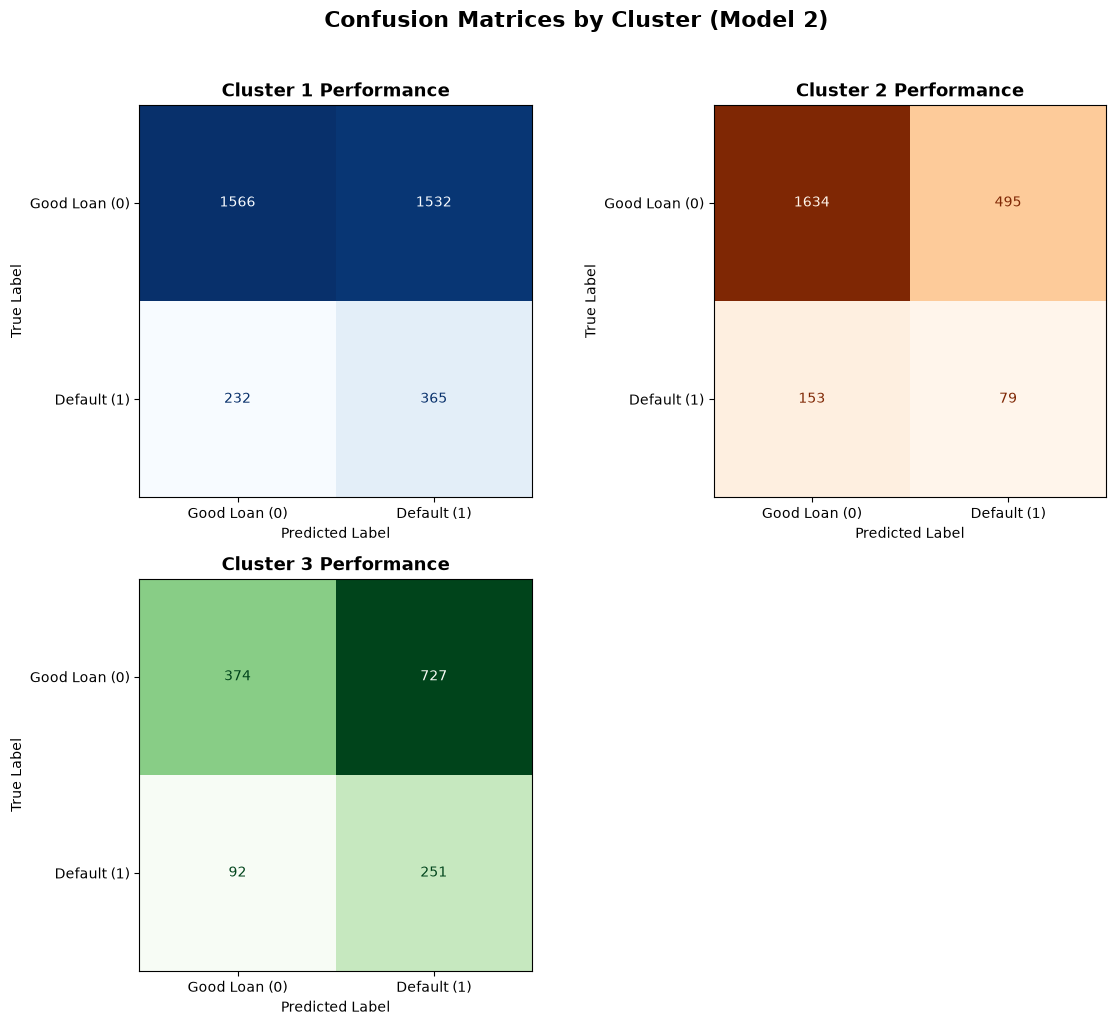

In [48]:
num_clusters = len(cluster_results)
cols = 2
rows = math.ceil(num_clusters / cols)

# Create the figure (12 inches wide, 5 inches tall per row)
fig, axes = plt.subplots(rows, cols, figsize=(12, 5 * rows))


axes = axes.flatten()

labels = ['Good Loan (0)', 'Default (1)']
colormaps = ['Blues', 'Oranges', 'Greens', 'Purples', 'Reds']


#  Loop through and Plot

for idx, (cluster_id, data) in enumerate(cluster_results.items()):
    actuals = data['actuals']
    probs = data['probs']

    # Apply threshold
    preds = (probs > 0.5).astype(int)

    # Generate the matrix
    cm = confusion_matrix(actuals, preds)

    # Plot it on the correct subplot
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
    disp.plot(ax=axes[idx], cmap=colormaps[idx % len(colormaps)], colorbar=False)

    # Format the titles
    axes[idx].set_title(f'Cluster {cluster_id} Performance', fontweight='bold', fontsize=13)
    axes[idx].set_xlabel('Predicted Label')
    axes[idx].set_ylabel('True Label')


for i in range(num_clusters, len(axes)):
    fig.delaxes(axes[i])

plt.suptitle('Confusion Matrices by Cluster (Model 2)',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()

plt.show()

## Model 3 (Model 1 with SMOTE)


PERFORMANCE FOR CLUSTER 1
Cluster 1 ROC-AUC Score: 0.6046

Classification Report for Cluster 1:
              precision    recall  f1-score   support

         0.0       0.88      0.44      0.59      3098
         1.0       0.20      0.70      0.31       597

    accuracy                           0.48      3695
   macro avg       0.54      0.57      0.45      3695
weighted avg       0.77      0.48      0.54      3695


PERFORMANCE FOR CLUSTER 2
Cluster 2 ROC-AUC Score: 0.6255

Classification Report for Cluster 2:
              precision    recall  f1-score   support

         0.0       0.91      0.88      0.89      2129
         1.0       0.15      0.19      0.17       232

    accuracy                           0.81      2361
   macro avg       0.53      0.54      0.53      2361
weighted avg       0.83      0.81      0.82      2361


PERFORMANCE FOR CLUSTER 3
Cluster 3 ROC-AUC Score: 0.6177

Classification Report for Cluster 3:
              precision    recall  f1-score   support



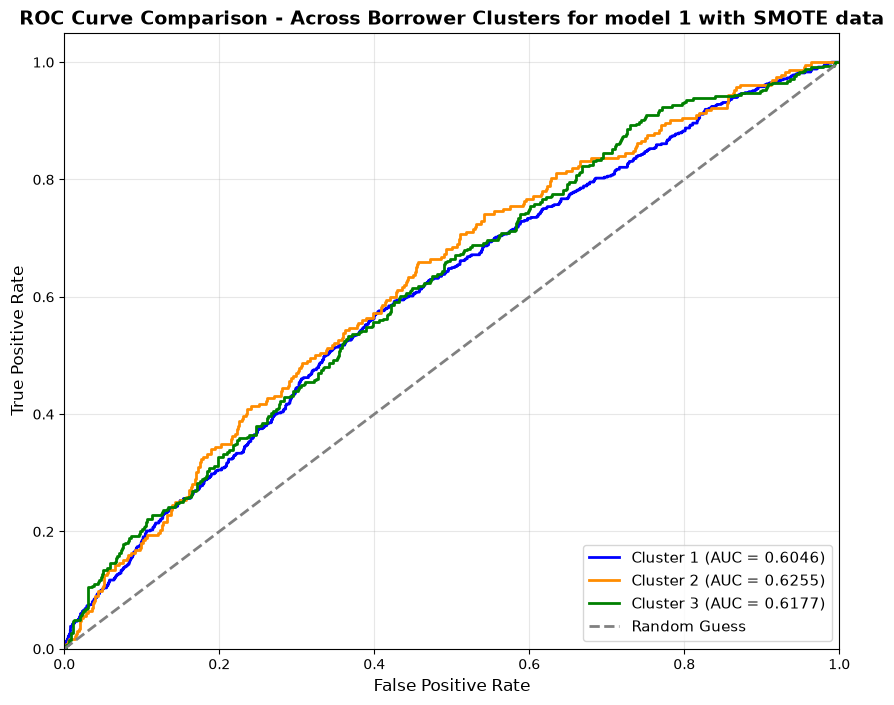

In [49]:
model1_smote.eval()

# Ask the model where it is currently living
device = next(model1_smote.parameters()).device

# Create a dictionary to store the results for each cluster!
cluster_results = {}

test_data = data_clean.loc[test_idx]  # evaluate on held-out test loans only

for cluster_id in sorted(test_data['cluster'].unique()):
    print(f"\n{'='*50}")
    print(f"PERFORMANCE FOR CLUSTER {cluster_id}")
    print(f"{'='*50}")

    # Isolate the data for just this cluster
    cluster_data = test_data[test_data['cluster'] == cluster_id]

    # Split into features (X) and target (y)
    X_cluster = cluster_data.drop(columns=['loan_is_bad', 'cluster'])
    y_cluster = cluster_data['loan_is_bad']

    # Scale the features
    X_cluster_scaled = scaler.transform(X_cluster)

    # Convert to PyTorch Tensors
    X_tensor = torch.tensor(X_cluster_scaled, dtype=torch.float32)
    y_tensor = torch.tensor(y_cluster.values, dtype=torch.float32).reshape(-1, 1)

    # Create a DataLoader specifically for THIS cluster
    cluster_dataset = TensorDataset(X_tensor, y_tensor)
    cluster_loader = DataLoader(cluster_dataset, batch_size=32, shuffle=False)

    all_actuals = []
    all_pred_probs = []

    with torch.no_grad():
        for inputs, targets in cluster_loader:
            inputs, targets = inputs.to(device), targets.to(device)


            probs = model1_smote(inputs)

            all_pred_probs.extend(probs.cpu().numpy())
            all_actuals.extend(targets.cpu().numpy())

    all_pred_probs = np.array(all_pred_probs)
    all_actuals = np.array(all_actuals)

    # SAVE the actuals and probabilities into our dictionary for plotting later!
    cluster_results[cluster_id] = {
        'actuals': all_actuals,
        'probs': all_pred_probs
    }

    # Convert probabilities to strict 0 or 1 predictions for the classification report
    all_pred_classes = (all_pred_probs > 0.5).astype(int)

    # Print the Metrics for this specific cluster
    if len(np.unique(all_actuals)) > 1:
        cluster_auc = roc_auc_score(all_actuals, all_pred_probs)
        print(f"Cluster {cluster_id} ROC-AUC Score: {cluster_auc:.4f}\n")
    else:
        print("ROC-AUC Score: Cannot calculate (only one class present)\n")

    print(f"Classification Report for Cluster {cluster_id}:")
    print(classification_report(all_actuals, all_pred_classes, zero_division=0))



plt.figure(figsize=(10, 8))
colors = ['blue', 'darkorange', 'green'] # Add more colors if you have more than 3 clusters!

# Loop through our saved dictionary to plot each line
for i, (cluster_id, data) in enumerate(cluster_results.items()):
    actuals = data['actuals']
    probs = data['probs']

    # Only plot if the cluster has both classes (0 and 1)
    if len(np.unique(actuals)) > 1:
        fpr, tpr, _ = roc_curve(actuals, probs)
        cluster_auc = auc(fpr, tpr)

        plt.plot(fpr, tpr, color=colors[i % len(colors)], lw=2,
                 label=f'Cluster {cluster_id} (AUC = {cluster_auc:.4f})')

# Plot the Random Guess Line
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--', label='Random Guess')

# Format the plot
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curve Comparison - Across Borrower Clusters for model 1 with SMOTE data', fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=11)
plt.grid(alpha=0.3)

plt.show()

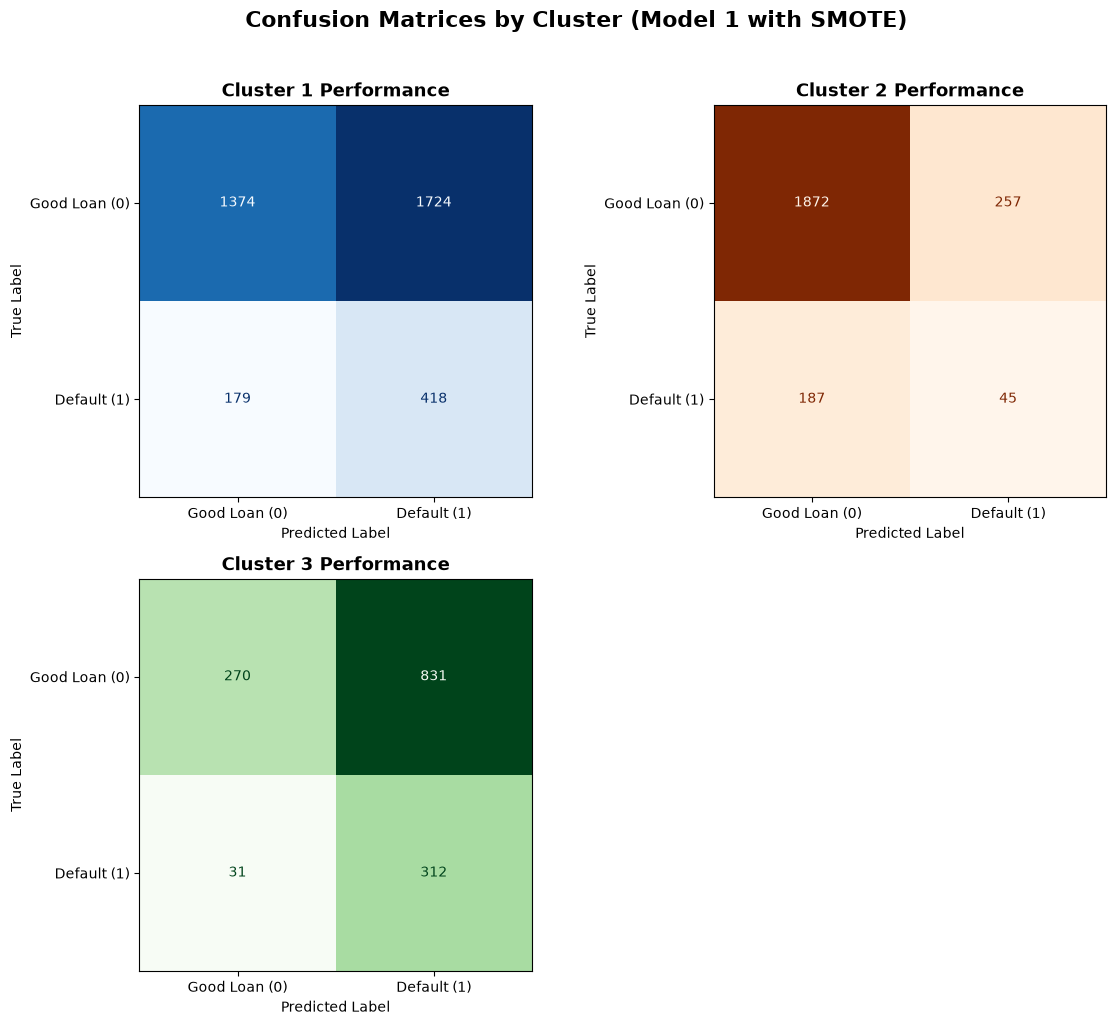

In [50]:
num_clusters = len(cluster_results)
cols = 2
rows = math.ceil(num_clusters / cols)

# Create the figure (12 inches wide, 5 inches tall per row)
fig, axes = plt.subplots(rows, cols, figsize=(12, 5 * rows))


axes = axes.flatten()

labels = ['Good Loan (0)', 'Default (1)']
colormaps = ['Blues', 'Oranges', 'Greens', 'Purples', 'Reds']


#  Loop through and Plot

for idx, (cluster_id, data) in enumerate(cluster_results.items()):
    actuals = data['actuals']
    probs = data['probs']

    # Apply threshold
    preds = (probs > 0.5).astype(int)

    # Generate the matrix
    cm = confusion_matrix(actuals, preds)

    # Plot it on the correct subplot
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
    disp.plot(ax=axes[idx], cmap=colormaps[idx % len(colormaps)], colorbar=False)

    # Format the titles
    axes[idx].set_title(f'Cluster {cluster_id} Performance', fontweight='bold', fontsize=13)
    axes[idx].set_xlabel('Predicted Label')
    axes[idx].set_ylabel('True Label')


for i in range(num_clusters, len(axes)):
    fig.delaxes(axes[i])

plt.suptitle('Confusion Matrices by Cluster (Model 1 with SMOTE)',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()

plt.show()

**Across the three models:** they are best at catching defaulters in cluster 3 (high-risk borrowers) but approve few good loans there; the reverse is true for cluster 2 (low risk), with cluster 1 (medium risk) in between.

On held-out test loans, **Model 1 has the highest ROC-AUC in every segment** and Model 2 the lowest. (In the original version, which scored all 50,000 loans including the training data, Model 2 appeared best because it had overfitted to the training loans.)